In [3]:
%pip install pandas

Note: you may need to restart the kernel to use updated packages.


In [2]:
!which python

/home/nudge/miniforge3/envs/drugai/bin/python


In [1]:
import sys
print(sys.executable)

/home/nudge/miniforge3/envs/Pocket2Mol/bin/python


In [1]:
!grep "\[Validate\]" training_log.txt

[2025-11-15 15:13:20,235::train::INFO] [Validate]  Iter 5000 | Loss 4.548611 | Loss(Fron) 0.204248 | Loss(Pos) 2.780275 | Loss(Cls) 1.023875 | Loss(Edge) 0.085300 | Loss(Real) 0.163672 | Loss(Fake) 0.245713  | Loss(Surf) 0.045529
[2025-11-15 15:26:06,773::train::INFO] [Validate]  Iter 10000 | Loss 3.716728 | Loss(Fron) 0.166277 | Loss(Pos) 2.121883 | Loss(Cls) 0.947818 | Loss(Edge) 0.081571 | Loss(Real) 0.090876 | Loss(Fake) 0.277391  | Loss(Surf) 0.030912
[2025-11-15 15:38:43,582::train::INFO] [Validate]  Iter 15000 | Loss 3.214882 | Loss(Fron) 0.185420 | Loss(Pos) 1.708422 | Loss(Cls) 0.921570 | Loss(Edge) 0.094379 | Loss(Real) 0.113102 | Loss(Fake) 0.177363  | Loss(Surf) 0.014625
[2025-11-15 15:51:18,569::train::INFO] [Validate]  Iter 20000 | Loss 3.488972 | Loss(Fron) 0.153248 | Loss(Pos) 1.980354 | Loss(Cls) 0.886374 | Loss(Edge) 0.094020 | Loss(Real) 0.083620 | Loss(Fake) 0.266519  | Loss(Surf) 0.024837
[2025-11-15 16:03:57,274::train::INFO] [Validate]  Iter 25000 | Loss 3.459704

In [2]:
!tail -n 100 training_log.txt

Validate: 100%|██████████| 50/50 [00:02<00:00, 20.88it/s]
[2025-11-16 11:30:34,034::train::INFO] [Validate]  Iter 500000 | Loss 1.589915 | Loss(Fron) 0.088469 | Loss(Pos) 0.527859 | Loss(Cls) 0.776988 | Loss(Edge) 0.049817 | Loss(Real) 0.039068 | Loss(Fake) 0.092446  | Loss(Surf) 0.015269
Training: 100%|██████████| 500000/500000 [20:30:01<00:00,  6.77it/s, Loss=4.2010, LR=1.00e-05, Next_Val=0]


In [7]:
# 셀 1--- [ 1. 설정 ] ---

# (필수!) 'samples_all.pt' 파일이 들어있는 폴더 이름을 정확히 입력하세요.
# (예: 'Pocket2Mol_2025_11_16__12_30_00')
EXP_NAME = "sample_0_2025_11_16__12_13_06"  

# (확인) 샘플링 결과가 저장된 상위 디렉토리입니다.
RESULT_ROOT = "/home/nudge/Pocket2Mol/outputs"  

# (확인) PDB 파일들이 모여있는 경로입니다.
PROTEIN_ROOT = "/home/nudge/Pocket2Mol/evaluation/pdb_data"  

# (확인) 도킹에 사용할 Conda 환경 이름입니다.
DOCKING_ENV_NAME = "adt"


# --- 설정된 경로 확인 ---
import os
exp_dir = os.path.join(RESULT_ROOT, EXP_NAME)
sample_path = os.path.join(exp_dir, 'samples_all.pt')

print(f"✅ 평가 대상 폴더: {exp_dir}")
print(f"✅ 샘플 파일 경로: {sample_path}")
if not os.path.exists(sample_path):
    print(f"\n⚠️ 경고: '{sample_path}' 파일을 찾을 수 없습니다.")
    print("-> EXP_NAME 변수 값을 다시 확인해주세요!")
else:
    print("-> 샘플 파일을 찾았습니다. 다음 셀을 실행하세요.")

✅ 평가 대상 폴더: /home/nudge/Pocket2Mol/outputs/sample_0_2025_11_16__12_13_06
✅ 샘플 파일 경로: /home/nudge/Pocket2Mol/outputs/sample_0_2025_11_16__12_13_06/samples_all.pt
-> 샘플 파일을 찾았습니다. 다음 셀을 실행하세요.


In [8]:
# 셀 2 --- [ 2. 필요 모듈 임포드]

import os
import sys
import torch
from tqdm.auto import tqdm
from rdkit.Chem.QED import qed
from rdkit import Chem

# 현재 폴더(Pocket2Mol)를 파이썬 경로에 추가
sys.path.append('.')

try:
    # 1. 분자 재구성 유틸리티
    from utils.reconstruct import reconstruct_from_generated_with_edges
    
    # 2. SA Score 계산기 (evaluation/sascorer.py)
    # (sascorer.py의 calculateScore 함수를 compute_sa_score 이름으로 가져옴)
    from evaluation.sascorer import calculateScore as compute_sa_score
    
    # 3. 도킹 태스크 (evaluation/docking.py)
    from evaluation.docking import QVinaDockingTask
    
    # 4. 기타 유틸리티 (utils/misc.py, evaluation/scoring_func.py)
    from utils.misc import get_logger
    from evaluation.scoring_func import obey_lipinski, get_logp
    
    print("--- ✅ 모든 평가 모듈 임포트 완료 ---")
    
except ModuleNotFoundError as e:
    print(f"\n[오류] 모듈을 찾지 못했습니다: {e}")
    print("-> 1. 현재 노트북이 'Pocket2Mol' 폴더에서 실행 중인지 확인하세요.")
    print("-> 2. 'evaluation' 폴더 안에 'docking.py', 'sascorer.py' 등이 있는지 확인하세요.")
except ImportError as e:
    print(f"\n[오류] 임포트 중 문제가 발생했습니다: {e}")

--- ✅ 모든 평가 모듈 임포트 완료 ---


In [9]:
# 셀 3 --- [ 2. 경로 및 로거 설정 ] ---
# (셀 1에서 정의한 변수 사용)
exp_dir = os.path.join(RESULT_ROOT, EXP_NAME)
sample_path = os.path.join(exp_dir, 'samples_all.pt')

logger = get_logger('evaluate_notebook', exp_dir)
logger.info(f"--- 평가 시작: {EXP_NAME} ---")
logger.info(f"샘플 파일: {sample_path}")
logger.info(f"단백질 데이터: {PROTEIN_ROOT}")
logger.info(f"도킹 환경: {DOCKING_ENV_NAME}")

# --- [ 3. 샘플 로드 ] ---
try:
    # (이전 버전의 PyTorch이므로 weights_only 인수를 사용하지 않음)
    samples = torch.load(sample_path, map_location='cpu')
    
    logger.info(f"총 {len(samples.finished)}개의 완료된 샘플을 로드했습니다.")
    print(f"총 {len(samples.finished)}개의 샘플을 로드했습니다. 평가를 시작합니다...")
except FileNotFoundError:
    logger.error(f"파일을 찾을 수 없습니다: {sample_path}")
    print(f"오류: 샘플 파일({sample_path})을 찾을 수 없습니다. [셀 1]의 EXP_NAME을 확인하세요.")
    raise
except Exception as e:
    logger.error(f"샘플 로드 중 오류 발생: {e}")
    print(f"샘플 파일({sample_path})을 로드하는 중 오류가 발생했습니다: {e}")
    raise

# --- [ 4. 메인 루프 ] ---
results = []
failed_indices = []

for i, data in enumerate(tqdm(samples.finished, desc="분자 평가 중")):
    try:
        # 1. 분자 재구성
        mol = reconstruct_from_generated_with_edges(data)
        if mol is None:
            raise ValueError("분자 재구성 실패 (mol is None)")
        Chem.SanitizeMol(mol)

        # 2. 도킹 작업 생성 및 실행
        vina_task = QVinaDockingTask.from_generated_data(
            data, 
            protein_root=PROTEIN_ROOT
        )
        vina_results = vina_task.run_sync() # 동기식으로 실행
        
        if not vina_results: # 도킹 결과가 빈 리스트([])이면
            raise ValueError("Vina 도킹 결과 없음")

        # 3. 화학적 속성 계산
        results.append({
            'index': i,
            'mol': mol,
            'smiles': Chem.MolToSmiles(mol),
            'vina': vina_results,                    # Vina 결과 (리스트)
            'best_affinity': vina_results[0]['affinity'], # 가장 좋은 점수
            'qed': qed(mol),
            'sa': compute_sa_score(mol),         # sascorer.py의 1-10점 척도
            'lipinski': obey_lipinski(mol),
            'logp': get_logp(mol),
        })

    except Exception as e:
        logger.warning(f"샘플 {i} 처리 실패: {e}")
        failed_indices.append(i)

# --- [ 5. 결과 요약 및 저장 ] ---
logger.info(f"--- 평가 완료 ---")
logger.info(f"총 {len(samples.finished)}개 중 {len(results)}개 성공, {len(failed_indices)}개 실패.")
print(f"\n평가 완료: {len(results)}개 성공 / {len(failed_indices)}개 실패")

if failed_indices:
    print(f"실패한 인덱스 (일부): {failed_indices[:20]}")
    print(f"자세한 내용은 '{exp_dir}/evaluate_notebook.log' 파일을 확인하세요.")

# 노트북용 결과 파일 저장
result_path = os.path.join(exp_dir, 'results_notebook.pt')
torch.save(results, result_path)

logger.info(f"최종 결과가 {result_path}에 저장되었습니다.")
print(f"최종 결과가 {result_path}에 저장되었습니다.")

[2025-11-16 12:44:39,476::evaluate_notebook::INFO] --- 평가 시작: sample_0_2025_11_16__12_13_06 ---
[2025-11-16 12:44:39,476::evaluate_notebook::INFO] --- 평가 시작: sample_0_2025_11_16__12_13_06 ---
[2025-11-16 12:44:39,476::evaluate_notebook::INFO] --- 평가 시작: sample_0_2025_11_16__12_13_06 ---
[2025-11-16 12:44:39,477::evaluate_notebook::INFO] 샘플 파일: /home/nudge/Pocket2Mol/outputs/sample_0_2025_11_16__12_13_06/samples_all.pt
[2025-11-16 12:44:39,477::evaluate_notebook::INFO] 샘플 파일: /home/nudge/Pocket2Mol/outputs/sample_0_2025_11_16__12_13_06/samples_all.pt
[2025-11-16 12:44:39,477::evaluate_notebook::INFO] 샘플 파일: /home/nudge/Pocket2Mol/outputs/sample_0_2025_11_16__12_13_06/samples_all.pt
[2025-11-16 12:44:39,478::evaluate_notebook::INFO] 단백질 데이터: /home/nudge/Pocket2Mol/evaluation/pdb_data
[2025-11-16 12:44:39,478::evaluate_notebook::INFO] 단백질 데이터: /home/nudge/Pocket2Mol/evaluation/pdb_data
[2025-11-16 12:44:39,478::evaluate_notebook::INFO] 단백질 데이터: /home/nudge/Pocket2Mol/evaluation/pdb_data
[

총 105개의 샘플을 로드했습니다. 평가를 시작합니다...


분자 평가 중:   1%|▎                            | 1/105 [00:00<01:09,  1.49it/s]

Best affinity: -4.2


분자 평가 중:   2%|▌                            | 2/105 [00:01<01:15,  1.36it/s]

...

Best affinity: -6.8


분자 평가 중:  99%|██████████████████████████▋| 104/105 [02:20<00:01,  1.38s/it]

Best affinity: -6.4


분자 평가 중: 100%|███████████████████████████| 105/105 [02:22<00:00,  1.36s/it]
[2025-11-16 12:47:02,889::evaluate_notebook::INFO] --- 평가 완료 ---
[2025-11-16 12:47:02,889::evaluate_notebook::INFO] --- 평가 완료 ---
[2025-11-16 12:47:02,889::evaluate_notebook::INFO] --- 평가 완료 ---
[2025-11-16 12:47:02,889::evaluate_notebook::INFO] 총 105개 중 104개 성공, 1개 실패.
[2025-11-16 12:47:02,889::evaluate_notebook::INFO] 총 105개 중 104개 성공, 1개 실패.
[2025-11-16 12:47:02,889::evaluate_notebook::INFO] 총 105개 중 104개 성공, 1개 실패.
[2025-11-16 12:47:02,910::evaluate_notebook::INFO] 최종 결과가 /home/nudge/Pocket2Mol/outputs/sample_0_2025_11_16__12_13_06/results_notebook.pt에 저장되었습니다.
[2025-11-16 12:47:02,910::evaluate_notebook::INFO] 최종 결과가 /home/nudge/Pocket2Mol/outputs/sample_0_2025_11_16__12_13_06/results_notebook.pt에 저장되었습니다.
[2025-11-16 12:47:02,910::evaluate_notebook::INFO] 최종 결과가 /home/nudge/Pocket2Mol/outputs/sample_0_2025_11_16__12_13_06/results_notebook.pt에 저장되었습니다.


Best affinity: -6.5

평가 완료: 104개 성공 / 1개 실패
실패한 인덱스 (일부): [80]
자세한 내용은 '/home/nudge/Pocket2Mol/outputs/sample_0_2025_11_16__12_13_06/evaluate_notebook.log' 파일을 확인하세요.
최종 결과가 /home/nudge/Pocket2Mol/outputs/sample_0_2025_11_16__12_13_06/results_notebook.pt에 저장되었습니다.


In [12]:
import pandas as pd
import sys
from rdkit.Chem import Draw
from rdkit.Chem.Draw import IPythonConsole
from IPython.display import display

# 'evaluation' 폴더가 있는 상위 폴더(.)를 경로에 추가
sys.path.append('.') 
try:
    # Novelty 계산에 필요한 클래스 임포트
    from evaluation.scoring_func import SimilarityWithTrain
except ImportError as e:
    print(f"[ImportError] {e}. 'evaluation.scoring_func'를 찾을 수 없습니다. 경로를 확인하세요.")
    SimilarityWithTrain = None # 임포트 실패 시 Novelty 계산을 건너뛰도록 설정

# [셀 3]에서 생성된 'results'와 'samples' 변수가 있는지 확인
if 'results' in locals() and 'samples' in locals() and results:
    
    # --- [ 1. V, U, N 기본 성능 지표 계산 ] ---
    print("--- 🔬 생성 모델 기본 성능 (V, U, N) 계산 ---")
    try:
        # 1. Validity (유효성)
        total_samples = len(samples.finished)
        valid_samples = len(results)
        validity_score = (valid_samples / total_samples) * 100 if total_samples > 0 else 0
        print(f"✅ Validity (유효성): {validity_score:.2f}%")
        print(f"   (총 시도 {total_samples}개 중 {valid_samples}개 성공)")

        if valid_samples > 0:
            # 2. Uniqueness (고유성)
            all_smiles = [r['smiles'] for r in results]
            unique_smiles_set = set(all_smiles)
            uniqueness_score = (len(unique_smiles_set) / valid_samples) * 100
            print(f"✅ Uniqueness (고유성): {uniqueness_score:.2f}%")
            print(f"   (유효한 분자 {valid_samples}개 중 {len(unique_smiles_set)}개 고유)")
            
            if unique_smiles_set and SimilarityWithTrain is not None:
                # 3. Novelty (참신성)
                print("\n... 훈련 세트 SMILES 로드 중 (Novelty 계산용) ...")
                sim_checker = SimilarityWithTrain()
                sim_checker._get_train_mols() # 훈련 데이터 SMILES 로드
                train_smiles_set = set(sim_checker.train_smiles)
                
                novel_smiles_set = unique_smiles_set - train_smiles_set
                novelty_score = (len(novel_smiles_set) / len(unique_smiles_set)) * 100
                print(f"✅ Novelty (참신성): {novelty_score:.2f}%")
                print(f"   (고유한 분자 {len(unique_smiles_set)}개 중 {len(novel_smiles_set)}개가 신규)")
            elif SimilarityWithTrain is None:
                 print("⚠️ Novelty: 'SimilarityWithTrain' 모듈을 임포트하지 못해 계산을 건너뜁니다.")
            else:
                print("⚠️ Novelty: 고유한 분자가 없어 계산할 수 없습니다.")
        else:
            print("⚠️ Uniqueness: 유효한 분자가 없어 계산할 수 없습니다.")
            print("⚠️ Novelty: 유효한 분자가 없어 계산할 수 없습니다.")

    except Exception as e:
        print(f"\n[오류] V, U, N 메트릭 계산 중 오류 발생: {e}")
        print("-> 'evaluation/scoring_func.py' 또는 학습 데이터 경로('data/crossdocked_pocket10_smiles.pt')를 확인하세요.")
    
    print("\n" + "="*50 + "\n") # --- 구분선 ---

    # --- [ 2. 속성 최적화 분석 (DataFrame) ] ---
    
    # DataFrame 생성
    df_data = []
    for r in results:
        df_data.append({
            'index': r.get('index'),
            'smiles': r.get('smiles'),
            'best_affinity': r.get('best_affinity'), # Vina (낮을수록 좋음)
            'qed': r.get('qed'),                     # QED (높을수록 좋음)
            'sa': r.get('sa'),                       # SA (낮을수록 좋음)
            'lipinski': r.get('lipinski'),           # Lipinski (높을수록 좋음, Max 5)
            'logp': r.get('logp')                    # LogP
        })
    df = pd.DataFrame(df_data)
    
    # 상위 5개 분자 선별 (Vina 결합력 기준)
    df_sorted = df.sort_values(by='best_affinity', ascending=True)
    
    print("--- 🔬 속성 평가 요약 (상위 5개) ---")
    display(df_sorted.head())
    
    # 전체 통계 요약
    print(f"\n--- 📈 전체 성공 샘플 통계 ({len(df)}개) ---")
    display(df[['best_affinity', 'qed', 'sa', 'lipinski', 'logp']].describe())
    
else:
    print("분석할 'results' 또는 'samples' 변수가 없습니다. [셀 3]이 성공적으로 실행되었는지 확인하세요.")

--- 🔬 생성 모델 기본 성능 (V, U, N) 계산 ---
✅ Validity (유효성): 99.05%
   (총 시도 105개 중 104개 성공)
✅ Uniqueness (고유성): 100.00%
   (유효한 분자 104개 중 104개 고유)

... 훈련 세트 SMILES 로드 중 (Novelty 계산용) ...
✅ Novelty (참신성): 100.00%
   (고유한 분자 104개 중 104개가 신규)


--- 🔬 속성 평가 요약 (상위 5개) ---


,index,smiles,best_affinity,qed,sa,lipinski,logp
13,13,C=C(C)C(C)Cc1ccccc1,-7.3,0.594068,2.327029,5,3.4413
85,86,C=C1OC(c2ccc(O)c(N)c2)=CC1=O,-7.3,0.411119,3.070598,5,1.4283
66,66,Nc1cccc(C=C2CC=COC2=O)c1,-7.3,0.429844,2.994761,5,2.1128
26,26,CC(=Cc1cccc(N)c1)C(=O)O,-7.2,0.534041,2.173692,5,1.7567
43,43,Nc1nc2nc(C(F)(F)F)ncc2[nH]1,-7.2,0.667548,2.949103,5,0.9539



--- 📈 전체 성공 샘플 통계 (104개) ---


,best_affinity,qed,sa,lipinski,logp
count,104.000000,104.000000,104.000000,104.0,104.000000
mean,-6.315385,0.607438,3.040828,5.0,0.896758
std,0.574502,0.108265,0.848935,0.0,1.034755
min,-7.300000,0.298626,1.644203,5.0,-1.567300
25%,-6.700000,0.535751,2.411054,5.0,0.292325
50%,-6.400000,0.639375,2.951529,5.0,0.946750
75%,-6.100000,0.695085,3.377606,5.0,1.412925
max,-4.200000,0.786208,5.547126,5.0,3.742300


--- 💊 상위 5개 분자 구조 (찌그러짐 없는 개별 뷰) ---

--- Index: 13 | Affinity: -7.30 ---


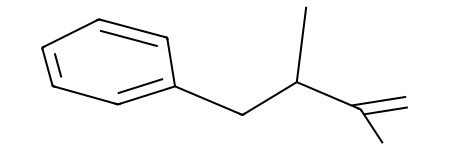


--- Index: 86 | Affinity: -7.30 ---


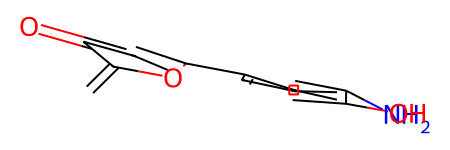


--- Index: 66 | Affinity: -7.30 ---


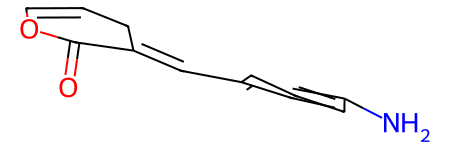


--- Index: 26 | Affinity: -7.20 ---


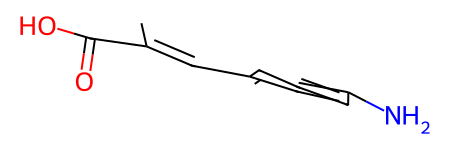


--- Index: 43 | Affinity: -7.20 ---


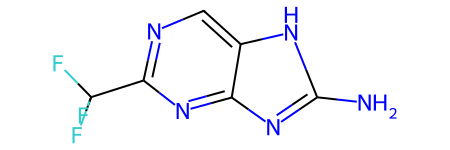

In [11]:
from IPython.display import display, HTML
import pandas as pd
from rdkit.Chem import Draw

# [셀 4+5]에서 생성된 변수들을 사용합니다.
if 'df_sorted' in locals() and 'mol_map' in locals() and 'df' in locals():
    
    print("--- 💊 상위 5개 분자 구조 (찌그러짐 없는 개별 뷰) ---")
    
    # 정렬된 DataFrame에서 상위 5개의 'index'를 가져옴
    top_5_indices = df_sorted.head()['index'].tolist()
    
    for idx in top_5_indices:
        # 1. 분자 정보 가져오기
        mol = mol_map[idx]
        affinity = df[df['index'] == idx]['best_affinity'].values[0]
        
        # 2. 정보 출력 (범례)
        print(f"\n--- Index: {idx} | Affinity: {affinity:.2f} ---")
        
        # 3. 개별 분자 이미지 렌더링 (display 함수)
        #    이 방식은 MolsToGridImage와 달리 찌그러지지 않습니다.
        display(mol)

else:
    print("분석할 'df_sorted' 또는 'mol_map' 변수가 없습니다.")
    print("[셀 4+5]가 성공적으로 실행되었는지 확인하세요.")